# Phase 5: Interpretability and Error Analysis

### Step 1: Environment Setup



In [2]:
# Mounting Drive, installing neurokit2, making src/ importable, and defining project paths
from google.colab import drive
drive.mount('/content/drive')
!pip install -q neurokit2

import os, sys, zipfile, ast
PROJECT = '/content/drive/MyDrive/ecg-project'
OUT, MODEL_DIR, RESULTS = f'{PROJECT}/data_processed', f'{PROJECT}/models', f'{PROJECT}/results'
FIGS = f'{RESULTS}/figures'
sys.path.append(f'{PROJECT}/src')

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf, keras, neurokit2 as nk
import data
from sklearn.metrics import roc_auc_score

LEADS = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
CLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
THR = 0.462                                   # CNN threshold chosen on validation in Phase 3

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 17.9 MB/s eta 0:00:00


### Step 2: Loading Test Data, Diagnosis Codes and Models

In [3]:
# Loading test ECGs, full PTB-XL diagnosis codes and quality flags, and the 10 trained CNNs; verify their AUROC
X_test, yb_test = data.load_split('test')
ym_test = np.load(f'{OUT}/Ymulti_test.npy')
meta = pd.read_csv(f'{OUT}/metadata.csv', index_col='ecg_id')
tm = meta[meta['split'] == 'test'].copy()

ZIP = '/content/drive/MyDrive/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip'
QUALITY = ['baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker']
with zipfile.ZipFile(ZIP) as z:
    name = next(n for n in z.namelist() if n.endswith('ptbxl_database.csv'))
    db = pd.read_csv(z.open(name), index_col='ecg_id')
tm = tm.join(db[['scp_codes'] + QUALITY])
tm['scp_codes'] = tm['scp_codes'].apply(ast.literal_eval)

cnn_bin = [keras.models.load_model(f'{MODEL_DIR}/cnn_binary_s{s}.keras') for s in range(5)]
cnn_multi = [keras.models.load_model(f'{MODEL_DIR}/cnn_multi_s{s}.keras') for s in range(5)]
p_bin = np.mean([m.predict(X_test, batch_size=256, verbose=0) for m in cnn_bin], axis=0).ravel()
p_multi = np.mean([m.predict(X_test, batch_size=256, verbose=0) for m in cnn_multi], axis=0)

print(f"Task A ensemble AUROC: {roc_auc_score(yb_test, p_bin):.3f} (expected 0.943)")
print(f"Task B ensemble macro AUROC: {roc_auc_score(ym_test, p_multi, average='macro'):.3f} (expected 0.933)")

Task A ensemble AUROC: 0.943 (expected 0.943)
Task B ensemble macro AUROC: 0.933 (expected 0.933)


### Step 3: Grad-CAM for 1D ECGs

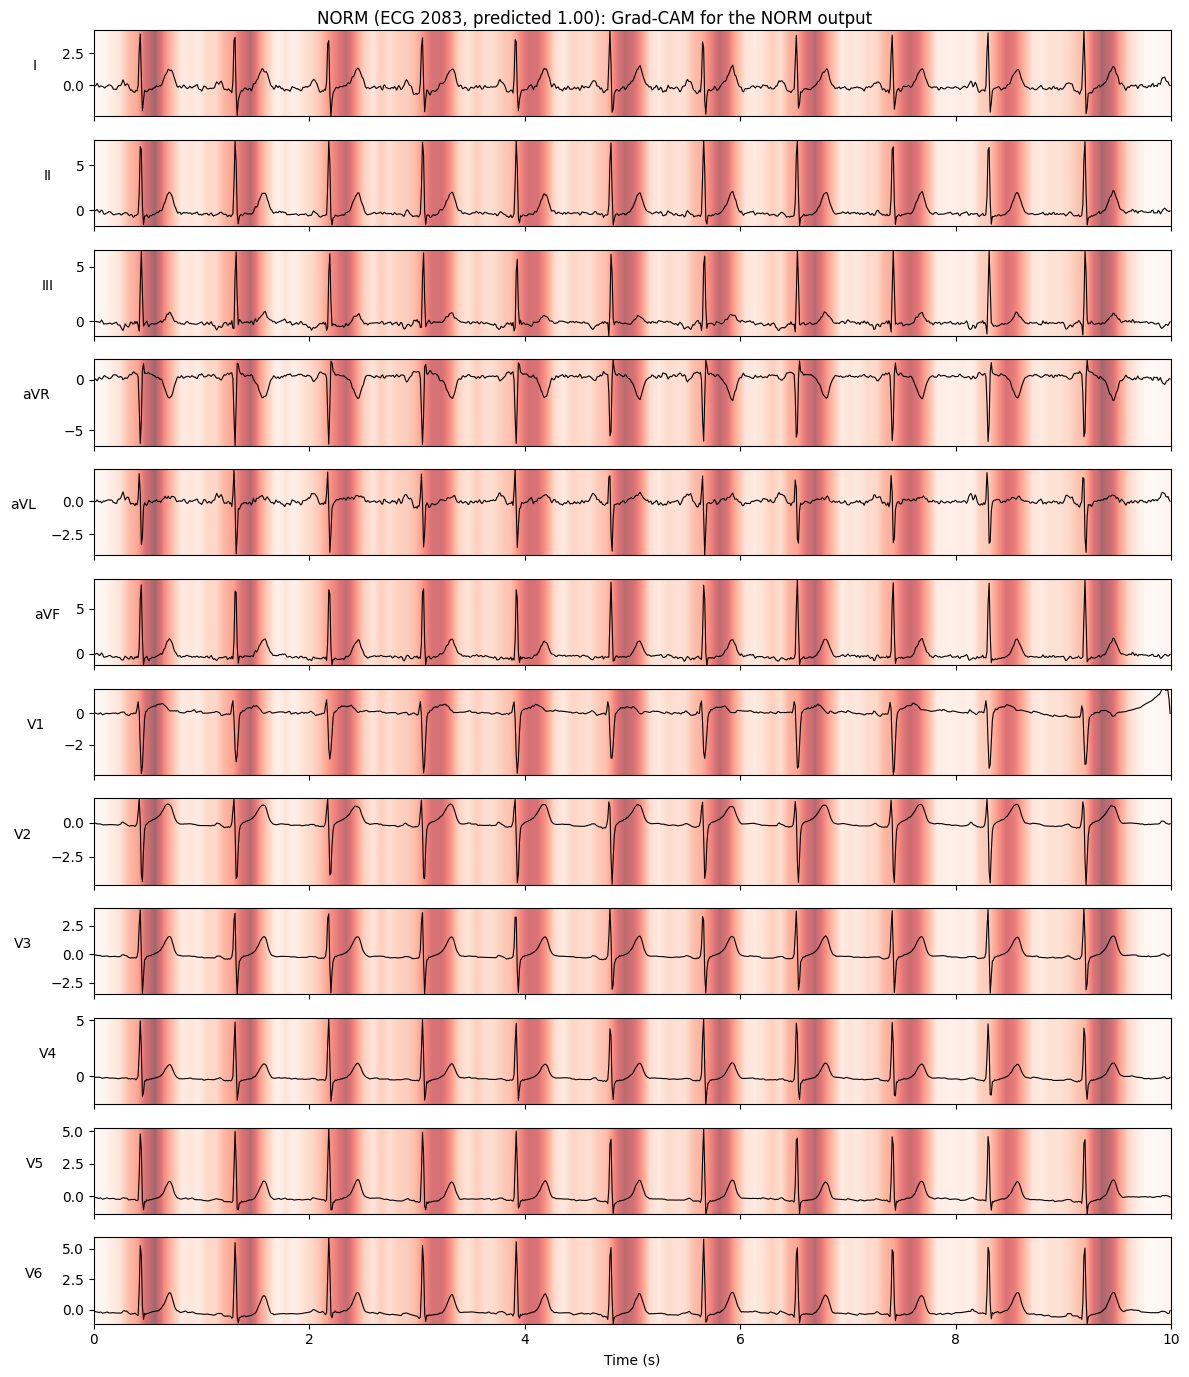

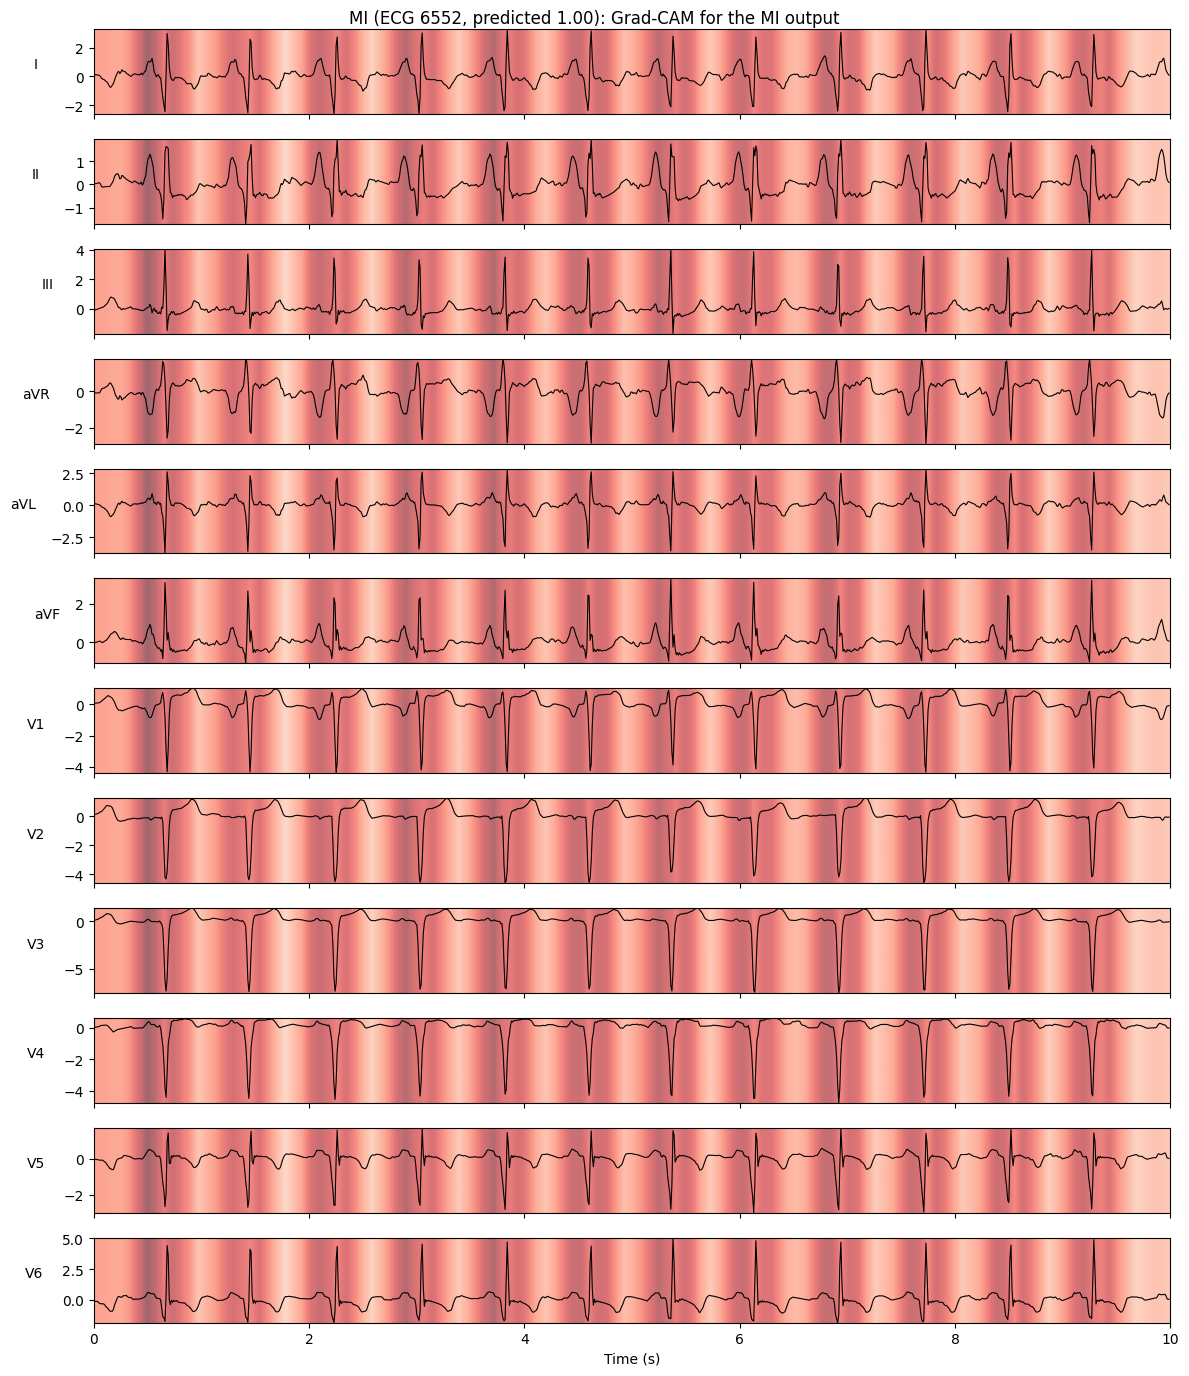

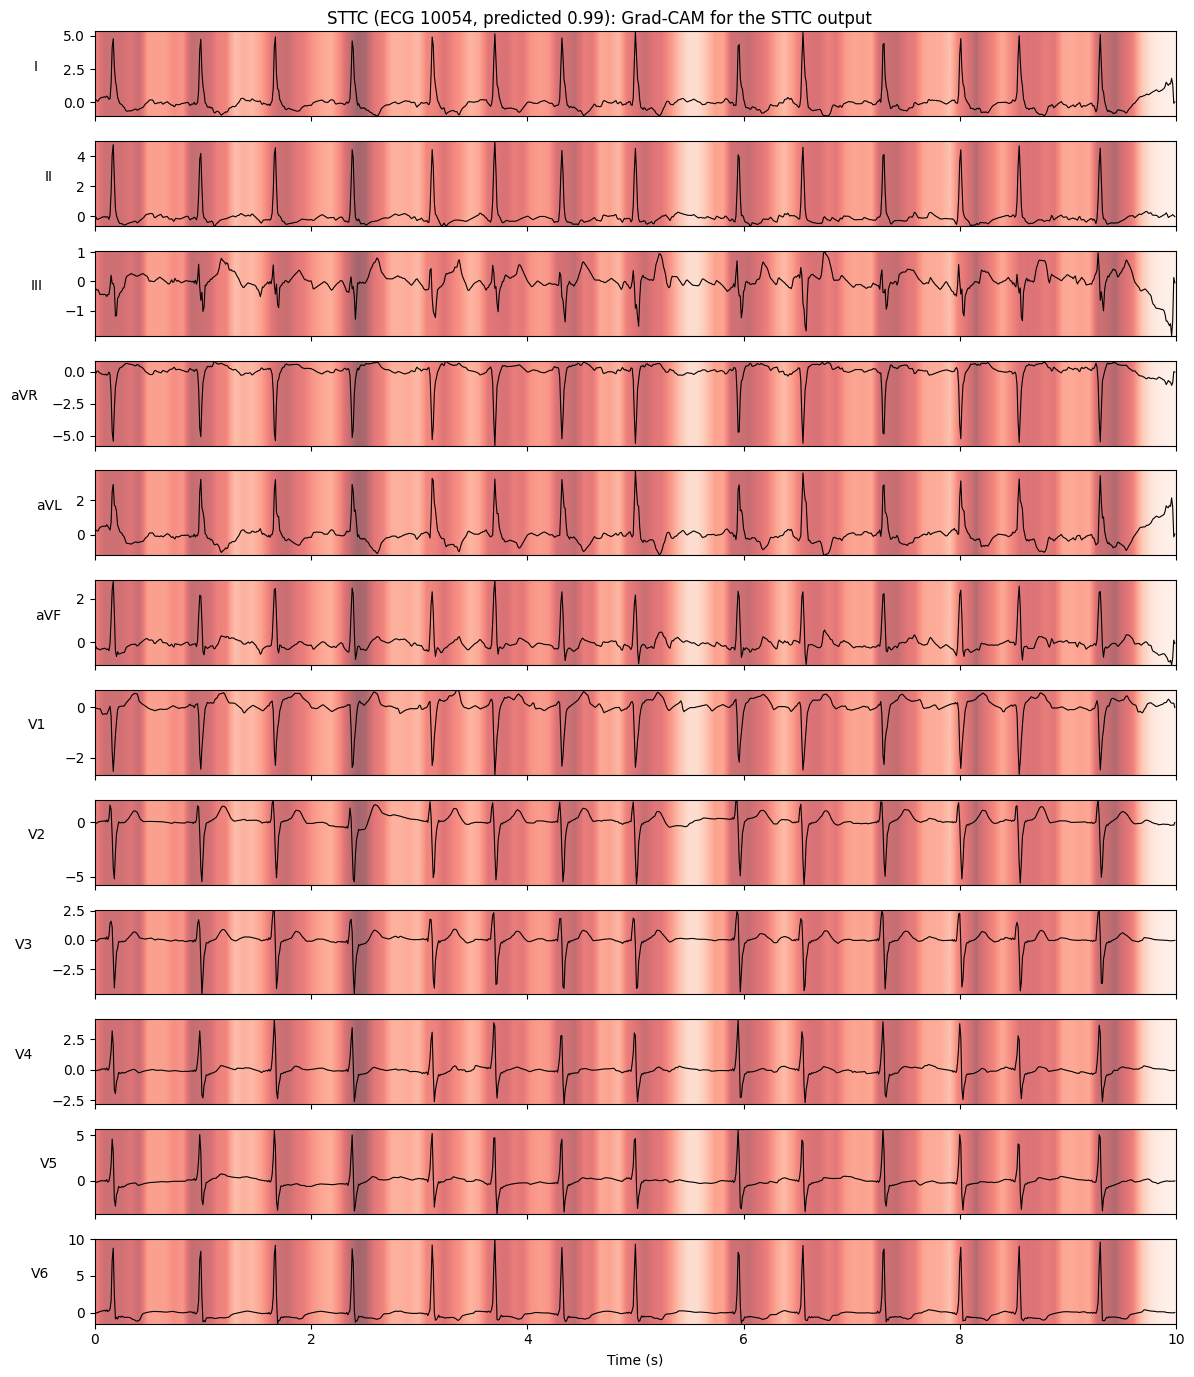

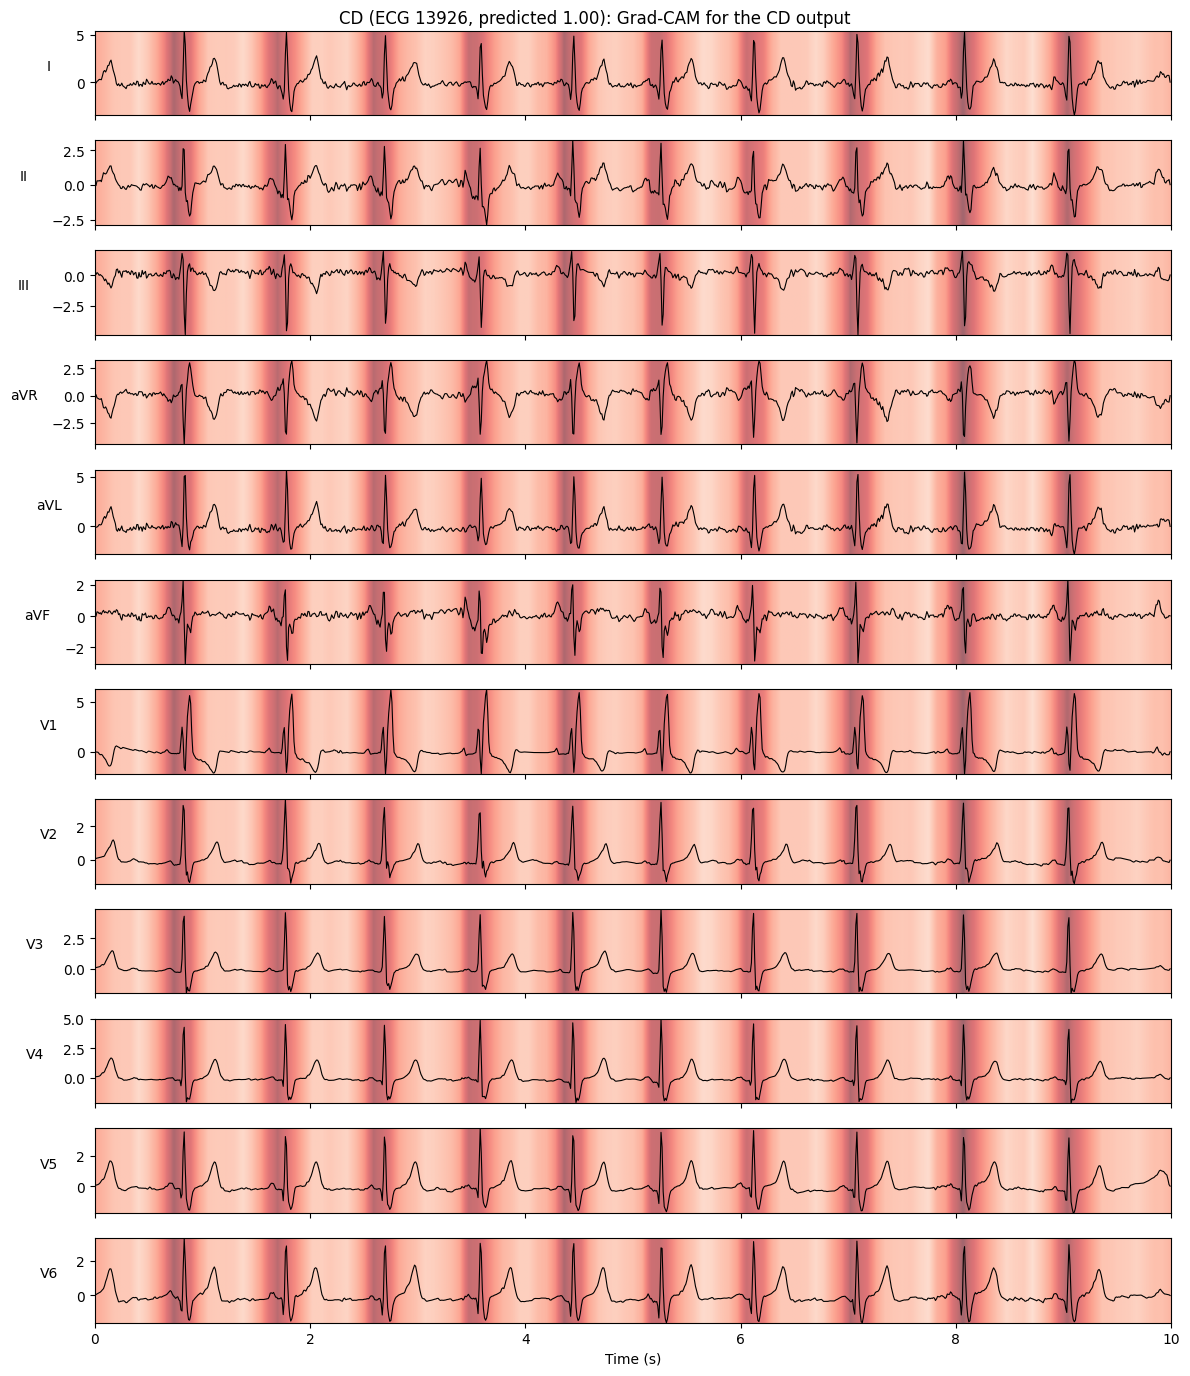

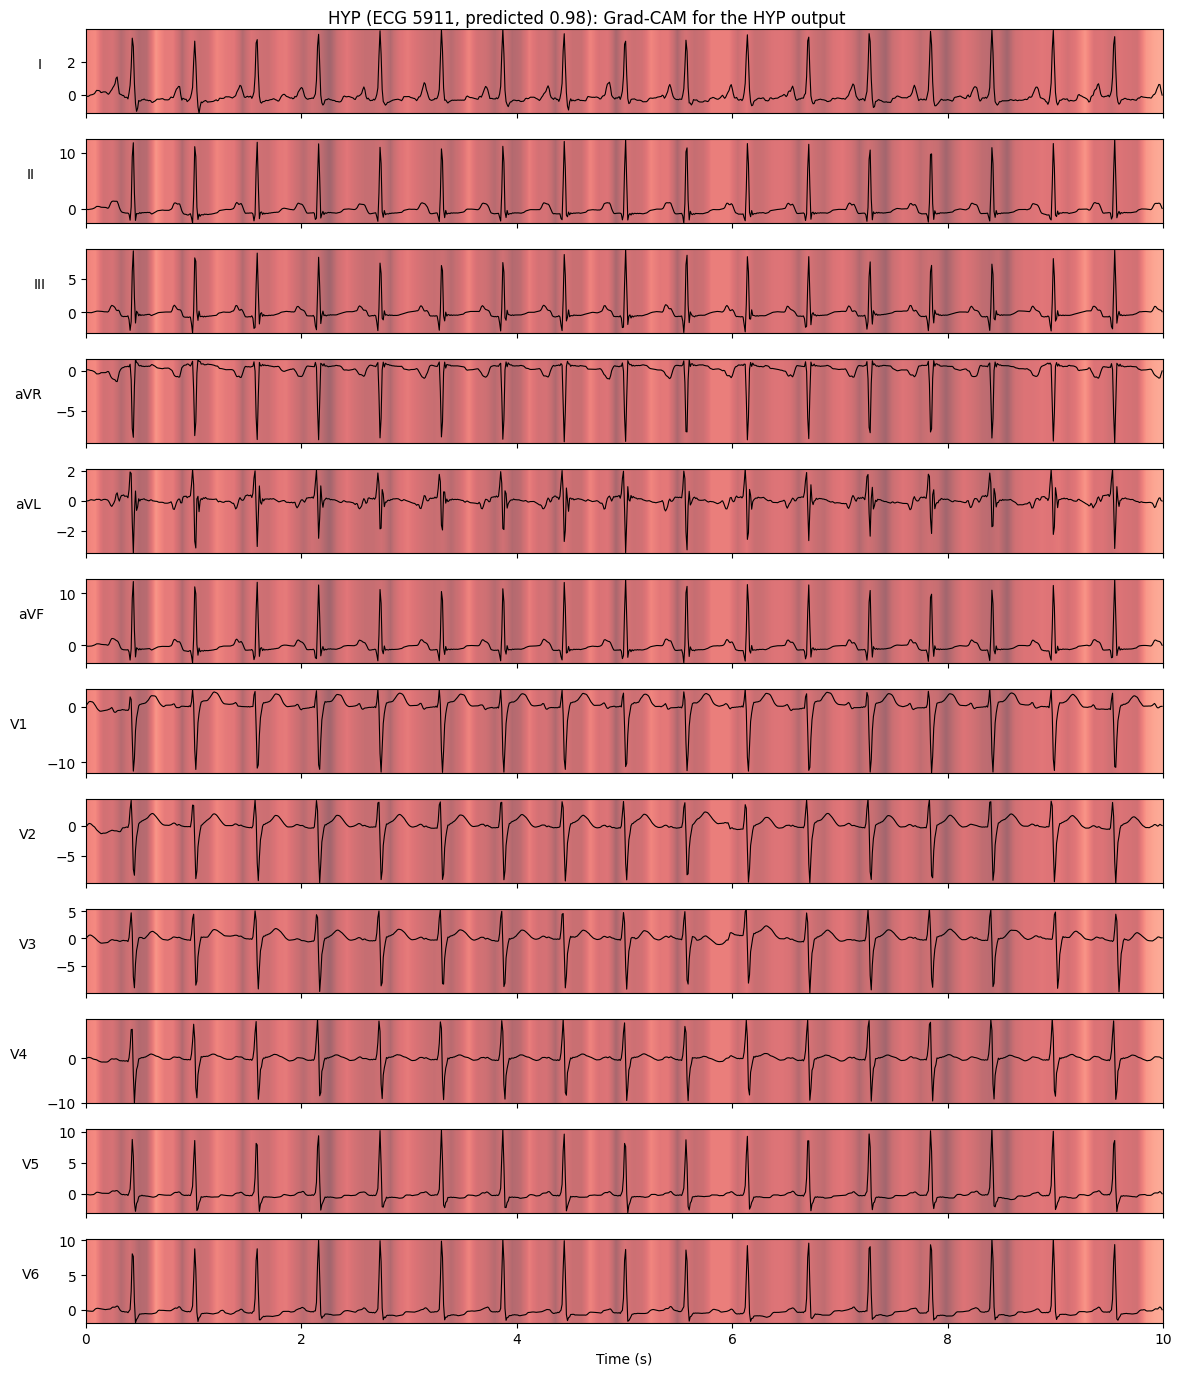

In [4]:
# Grad-CAM adapted to 1D signals: which time points drove a given output, averaged over the 5 seeds
def relu_layers(model):
    return [l.name for l in model.layers if isinstance(l, keras.layers.ReLU)]

def cam_models(models, block=3):
    """Expose the ReLU output of conv block 4 (125 steps, 80 ms each) alongside the prediction."""
    return [keras.Model(m.inputs, [m.get_layer(relu_layers(m)[block]).output, m.outputs[0]]) for m in models]

def grad_cam(gms, X, class_idx):
    X = tf.constant(X, tf.float32)
    cams = []
    for gm in gms:
        with tf.GradientTape() as tape:
            feats, preds = gm(X, training=False)
            score = preds[:, class_idx]
        grads = tape.gradient(score, feats)                          # (batch, time, channels)
        weights = tf.reduce_mean(grads, axis=1, keepdims=True)       # importance of each channel
        cam = tf.nn.relu(tf.reduce_sum(feats * weights, axis=-1)).numpy()
        cams.append(cam)
    cam = np.mean(cams, axis=0)
    T = X.shape[1]
    cam = np.stack([np.interp(np.arange(T), np.linspace(0, T - 1, c.size), c) for c in cam])
    return cam / (cam.max(axis=1, keepdims=True) + 1e-8)

gm_bin, gm_multi = cam_models(cnn_bin), cam_models(cnn_multi)

def plot_cam(ecg, cam, title, path=None):
    t = np.arange(len(ecg)) / 100
    fig, axes = plt.subplots(12, 1, figsize=(12, 14), sharex=True)
    for j, ax in enumerate(axes):
        lo, hi = ecg[:, j].min(), ecg[:, j].max()
        ax.imshow(cam[None, :], aspect='auto', cmap='Reds', alpha=0.6, extent=[0, 10, lo, hi], vmin=0, vmax=1)
        ax.plot(t, ecg[:, j], 'k', lw=0.8)
        ax.set_ylim(lo, hi)
        ax.set_ylabel(LEADS[j], rotation=0, labelpad=20)
    axes[-1].set_xlabel('Time (s)')
    fig.suptitle(title)
    plt.tight_layout()
    if path: plt.savefig(path, dpi=150)
    plt.show()

# One confident, correctly classified example for each pure (single-label) diagnostic class
pure = (tm['superclass'].str.split('|').str.len() == 1).values
for k, c in enumerate(CLASSES):
    idx = np.where(pure & (ym_test[:, k] == 1))[0]
    i = idx[np.argmax(p_multi[idx, k])]
    cam = grad_cam(gm_multi, X_test[i:i + 1], k)[0]
    plot_cam(X_test[i], cam, f'{c} (ECG {tm.index[i]}, predicted {p_multi[i, k]:.2f}): Grad-CAM for the {c} output',
             f'{FIGS}/gradcam_{c}.png')

### Step 4: Where in the Heartbeat Does the Model Look?

NORM: 200 ECGs
MI: 200 ECGs
STTC: 200 ECGs
CD: 200 ECGs
HYP: 129 ECGs


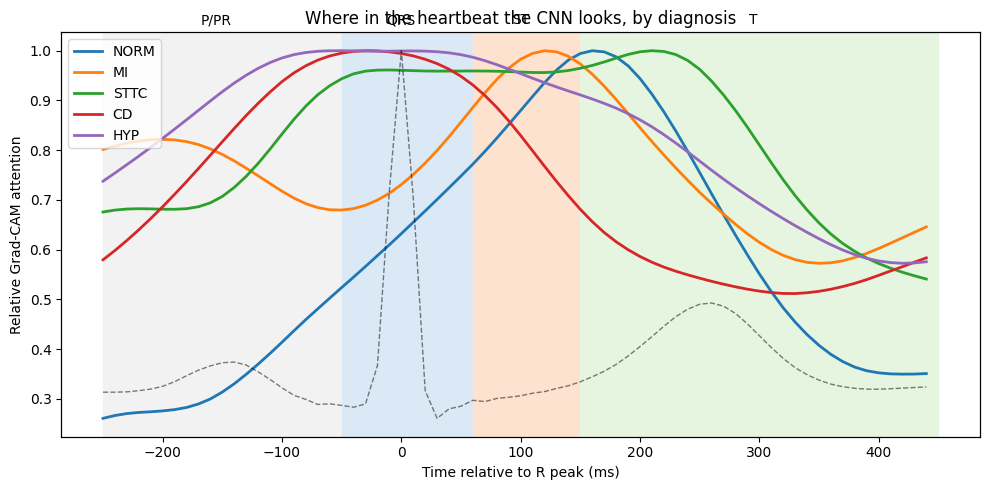


Attention density relative to the beat average (>1 = above-average focus):
      P/PR   QRS    ST     T
NORM  0.59  1.10  1.52  1.08
MI    1.01  0.98  1.27  0.92
STTC  0.90  1.15  1.15  0.96
CD    1.10  1.35  1.13  0.77
HYP   1.06  1.19  1.13  0.85


In [5]:
# Heartbeat-aligned Grad-CAM: average attention around each R peak, per diagnostic class (up to 200 correct ECGs each)
def beat_profile(ecg, cam):
    try:
        r = np.asarray(nk.ecg_peaks(ecg[:, 1], sampling_rate=100)[1]['ECG_R_Peaks'])
    except Exception:
        return None
    r = r[(r >= 25) & (r <= len(ecg) - 45)]
    return np.mean([cam[i - 25:i + 45] for i in r], axis=0) if len(r) else None

rng = np.random.default_rng(42)
profiles, beat_ref = {}, None
for k, c in enumerate(CLASSES):
    ok = (ym_test[:, k] == 1) & (p_multi[:, k] >= 0.5)
    if c == 'NORM':
        ok &= pure
    idx = rng.permutation(np.where(ok)[0])[:200]
    cams = np.concatenate([grad_cam(gm_multi, X_test[idx[j:j + 50]], k) for j in range(0, len(idx), 50)])
    prof = [beat_profile(X_test[i], cm) for i, cm in zip(idx, cams)]
    profiles[c] = np.mean([p for p in prof if p is not None], axis=0)
    if c == 'NORM':
        beat_ref = np.mean([beat_profile(X_test[i], X_test[i][:, 1]) for i in idx[:100]], axis=0)
    print(f'{c}: {len(idx)} ECGs')

ms = (np.arange(70) - 25) * 10
WINDOWS = {'P/PR': (0, 20), 'QRS': (20, 31), 'ST': (31, 40), 'T': (40, 70)}

fig, ax = plt.subplots(figsize=(10, 5))
for name, (a, b), col in zip(WINDOWS, WINDOWS.values(), ['#f2f2f2', '#dbe9f6', '#fde2cf', '#e5f5e0']):
    ax.axvspan(ms[a], ms[b - 1] + 10, color=col, zorder=0)
    ax.text((ms[a] + ms[b - 1]) / 2, 1.02, name, ha='center', transform=ax.get_xaxis_transform())
for c in CLASSES:
    ax.plot(ms, profiles[c] / profiles[c].max(), lw=2, label=c)
ax2 = ax.twinx()
ax2.plot(ms, beat_ref, 'k--', lw=1, alpha=0.5, label='average normal beat (lead II)')
ax2.set_yticks([])
ax.set(xlabel='Time relative to R peak (ms)', ylabel='Relative Grad-CAM attention',
       title='Where in the heartbeat the CNN looks, by diagnosis')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(f'{FIGS}/gradcam_beat_profiles.png', dpi=150)
plt.show()

density = pd.DataFrame({c: {w: profiles[c][a:b].mean() / profiles[c].mean() for w, (a, b) in WINDOWS.items()}
                        for c in CLASSES}).T.round(2)
density.to_csv(f'{RESULTS}/gradcam_window_density.csv')
print('\nAttention density relative to the beat average (>1 = above-average focus):')
print(density)

### Step 5: Lead Ablation

I: done
II: done
III: done
aVR: done
aVL: done
aVF: done
V1: done
V2: done
V3: done
V4: done
V5: done
V6: done
Limb leads (I-aVF): done
Chest leads (V1-V6): done


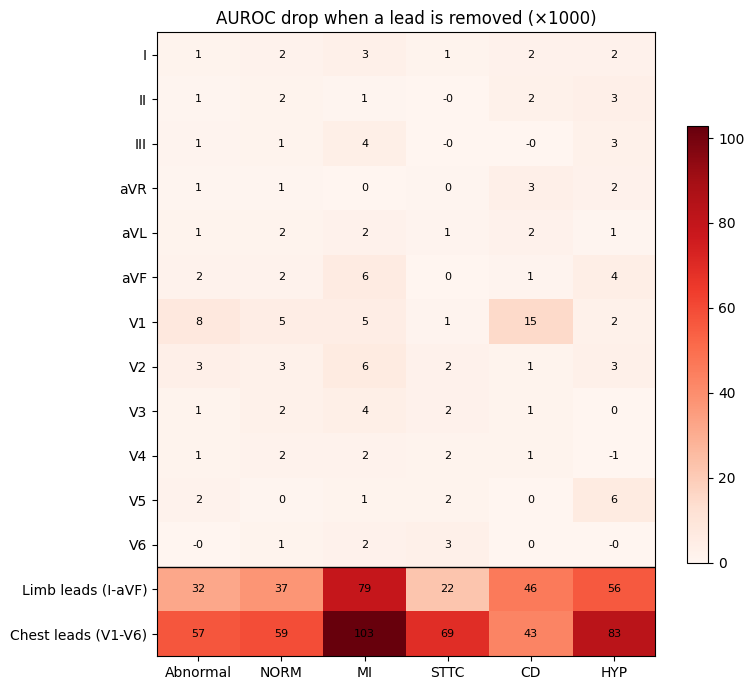

In [6]:
# Lead ablation: zero out one lead (or a lead group) at a time and measure the AUROC drop for Task A and each Task B class
def ens_predict(models, X):
    return np.mean([m.predict(X, batch_size=256, verbose=0) for m in models], axis=0)

base_bin = roc_auc_score(yb_test, p_bin)
base_multi = [roc_auc_score(ym_test[:, k], p_multi[:, k]) for k in range(5)]
ablations = {lead: [j] for j, lead in enumerate(LEADS)}
ablations.update({'Limb leads (I-aVF)': list(range(6)), 'Chest leads (V1-V6)': list(range(6, 12))})

rows = []
for name, cols in ablations.items():
    Xa = X_test.copy()
    Xa[:, :, cols] = 0
    pb, pm = ens_predict(cnn_bin, Xa).ravel(), ens_predict(cnn_multi, Xa)
    row = {'removed': name, 'Abnormal': base_bin - roc_auc_score(yb_test, pb)}
    row.update({c: base_multi[k] - roc_auc_score(ym_test[:, k], pm[:, k]) for k, c in enumerate(CLASSES)})
    rows.append(row)
    print(f'{name}: done')

abl = pd.DataFrame(rows).set_index('removed')
abl.to_csv(f'{RESULTS}/lead_ablation.csv')

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(abl.values * 1000, cmap='Reds', aspect='auto', vmin=0)
ax.set(xticks=range(abl.shape[1]), xticklabels=abl.columns, yticks=range(abl.shape[0]), yticklabels=abl.index,
       title='AUROC drop when a lead is removed (×1000)')
for i in range(abl.shape[0]):
    for j in range(abl.shape[1]):
        ax.text(j, i, f'{abl.values[i, j] * 1000:.0f}', ha='center', va='center', fontsize=8)
ax.axhline(11.5, color='k', lw=1)
plt.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()
plt.savefig(f'{FIGS}/lead_ablation.png', dpi=150)
plt.show()

### Step 6: Errors and Recording Quality

In [7]:
# Label each test ECG as correct / missed (FN) / false alarm (FP) at the CNN threshold, and compare noisy vs clean recordings
tm['y'], tm['p'] = yb_test.astype(int), p_bin
tm['error'] = np.select([(tm.y == 1) & (tm.p < THR), (tm.y == 0) & (tm.p >= THR)], ['FN', 'FP'], 'correct')
tm['noisy'] = tm[['baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems']].notna().any(axis=1)

for flag in ['noisy', 'extra_beats', 'pacemaker']:
    has = tm['noisy'] if flag == 'noisy' else tm[flag].notna()
    for val, sub in [(True, tm[has]), (False, tm[~has])]:
        auc = roc_auc_score(sub.y, sub.p) if sub.y.nunique() == 2 else np.nan
        print(f'{flag:12s} {str(val):5s} n={len(sub):5d} | error rate {(sub.error != "correct").mean():.3f} | AUROC {auc:.3f}')

cols = ['age', 'sex', 'p', 'superclass', 'scp_codes', 'noisy']
print('\nMost confident misses (abnormal ECGs scored lowest):')
print(tm[tm.error == 'FN'].nsmallest(10, 'p')[cols].to_string())
print('\nMost confident false alarms (normal ECGs scored highest):')
print(tm[tm.error == 'FP'].nlargest(10, 'p')[cols].to_string())

noisy        True  n=  513 | error rate 0.142 | AUROC 0.938
noisy        False n= 1645 | error rate 0.138 | AUROC 0.944
extra_beats  True  n=  192 | error rate 0.130 | AUROC 0.957
extra_beats  False n= 1966 | error rate 0.140 | AUROC 0.941
pacemaker    True  n=    2 | error rate 0.500 | AUROC nan
pacemaker    False n= 2156 | error rate 0.139 | AUROC 0.943

Most confident misses (abnormal ECGs scored lowest):
         age sex         p superclass                                      scp_codes  noisy
ecg_id                                                                                     
19461   42.0   F  0.007805    CD|NORM      {'NORM': 100.0, 'IVCD': 100.0, 'SR': 0.0}  False
3248    34.0   M  0.009585    CD|NORM       {'NORM': 80.0, 'IVCD': 100.0, 'SR': 0.0}  False
2909    48.0   F  0.014429    CD|NORM   {'NORM': 100.0, 'IVCD': 100.0, 'SBRAD': 0.0}  False
378     17.0   F  0.015930         CD                  {'LPFB': 100.0, 'SARRH': 0.0}   True
19081   17.0   M  0.016696         C

### Step 7: Which Diagnoses Are Missed?

In [8]:
# Miss rate per specific diagnostic code (abnormal test ECGs, codes with at least 15 cases) and the codes behind misses under 40
from collections import Counter

with zipfile.ZipFile(ZIP) as z:
    name = next(n for n in z.namelist() if n.endswith('scp_statements.csv'))
    scp = pd.read_csv(z.open(name), index_col=0)
diag = scp[scp['diagnostic'] == 1]

abn = tm[tm.y == 1]
rows = []
for code in diag.index:
    has = abn['scp_codes'].apply(lambda d: code in d)
    if has.sum() >= 15:
        rows.append({'code': code, 'description': diag.loc[code, 'description'], 'class': diag.loc[code, 'diagnostic_class'],
                     'n': has.sum(), 'missed': (abn.loc[has, 'error'] == 'FN').sum()})
codes = pd.DataFrame(rows)
codes['miss_rate'] = (codes.missed / codes.n).round(2)
codes = codes.sort_values('miss_rate', ascending=False)
codes.to_csv(f'{RESULTS}/miss_rate_by_code.csv', index=False)
print(codes.to_string(index=False))

young_fn = tm[(tm.error == 'FN') & (tm.age < 40)]
print(f'\nMissed abnormal ECGs under 40: {len(young_fn)}')
print(Counter(c for d in young_fn['scp_codes'] for c in d if c in diag.index).most_common(10))

   code                                                  description class   n  missed  miss_rate
   NORM                                                   normal ECG  NORM  51      28       0.55
   IVCD non-specific intraventricular conduction disturbance (block)    CD  79      32       0.41
    AMI                               anterior myocardial infarction    MI  35      10       0.29
   LPFB                              left posterior fascicular block    CD  18       4       0.22
    IMI                               inferior myocardial infarction    MI 267      51       0.19
LAO/LAE                             left atrial overload/enlargement   HYP  42       8       0.19
    NDT                               non-diagnostic T abnormalities  STTC 182      33       0.18
  IRBBB                         incomplete right bundle branch block    CD 112      20       0.18
    LVH                                 left ventricular hypertrophy   HYP 214      32       0.15
    LMI             

### Step 8: Grad-CAM on Confident Mistakes

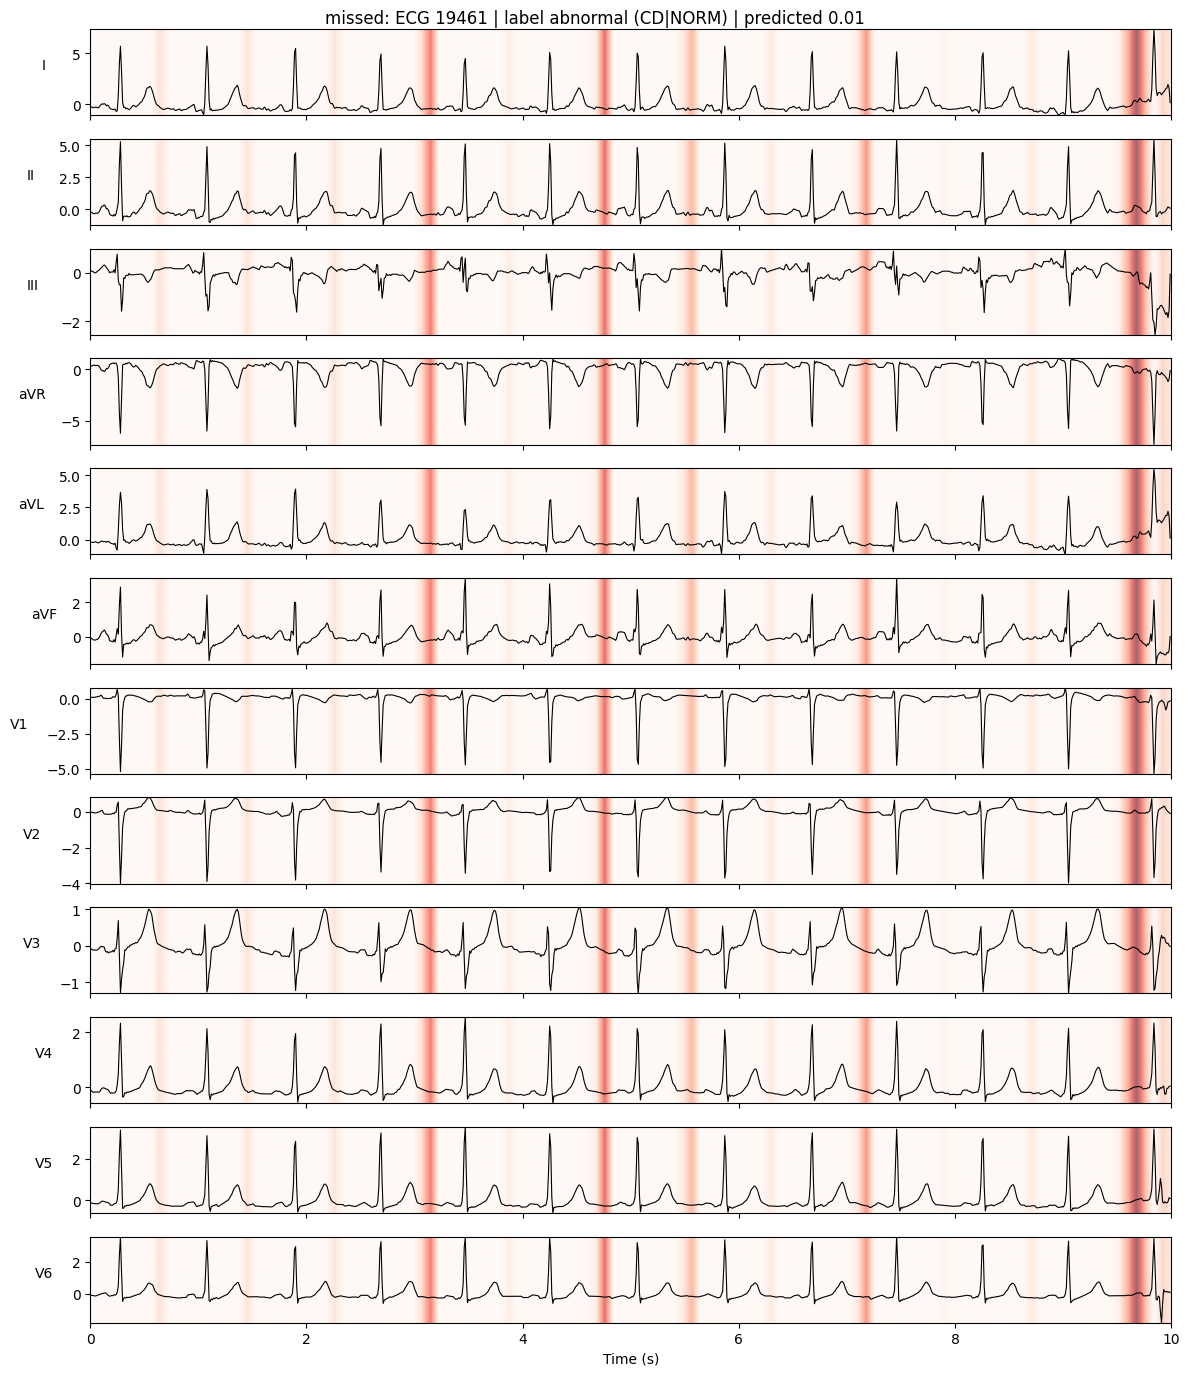

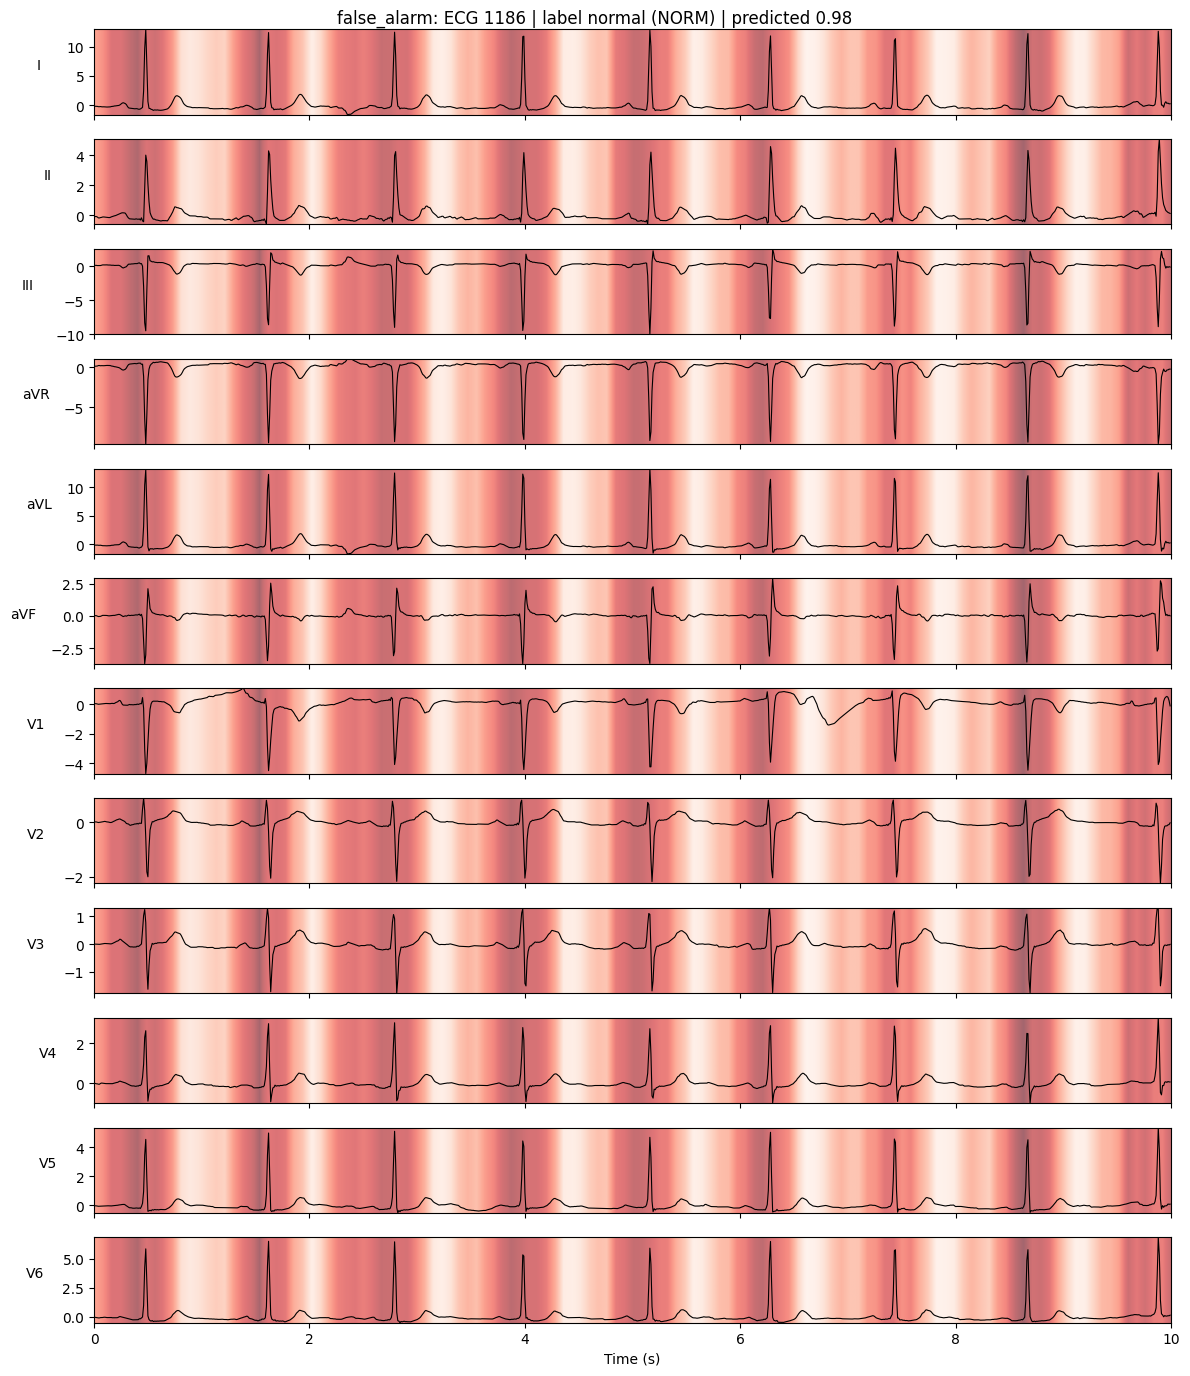

In [9]:
# Grad-CAM (Task A output) for the most confident miss and the most confident false alarm
for kind, sel in [('missed', tm[tm.error == 'FN'].nsmallest(1, 'p')), ('false_alarm', tm[tm.error == 'FP'].nlargest(1, 'p'))]:
    i = tm.index.get_loc(sel.index[0])
    cam = grad_cam(gm_bin, X_test[i:i + 1], 0)[0]
    plot_cam(X_test[i], cam, f'{kind}: ECG {tm.index[i]} | label {"abnormal" if tm.y.iloc[i] else "normal"} '
             f'({tm.superclass.iloc[i]}) | predicted {tm.p.iloc[i]:.2f}', f'{FIGS}/gradcam_error_{kind}.png')

### Step 9: Sensitivity Analysis - Mixed Labels

In [10]:
# How much of the remaining error, and of the age gap, comes from mixed labels?
mixed = (tm.y == 1) & tm['superclass'].str.split('|').apply(lambda s: 'NORM' in s)
abn_mask = tm.y == 1
print(f'Mixed-label ECGs (NORM + another class): {mixed.sum()} of {abn_mask.sum()} abnormal ECGs')
print(f'Miss rate: mixed {(tm.error[mixed] == "FN").mean():.2f} | other abnormal {(tm.error[abn_mask & ~mixed] == "FN").mean():.2f}\n')

def summarize(sel):
    sub = tm[sel]
    return {'n': len(sub), 'AUROC': roc_auc_score(sub.y, sub.p), 'Sensitivity': (sub.p[sub.y == 1] >= THR).mean(),
            'Specificity': (sub.p[sub.y == 0] < THR).mean()}

rows = []
for group, g in [('All ages', np.ones(len(tm), bool)), ('Under 40', (tm.age < 40).values), ('40 and over', (tm.age >= 40).values)]:
    rows.append({'group': group, 'labels': 'all', **summarize(g)})
    rows.append({'group': group, 'labels': 'mixed excluded', **summarize(g & ~mixed.values)})
sens = pd.DataFrame(rows).round(3)
sens.to_csv(f'{RESULTS}/mixed_label_sensitivity.csv', index=False)
print(sens.to_string(index=False))

Mixed-label ECGs (NORM + another class): 51 of 1246 abnormal ECGs
Miss rate: mixed 0.55 | other abnormal 0.16

      group         labels    n  AUROC  Sensitivity  Specificity
   All ages            all 2158  0.943        0.819        0.918
   All ages mixed excluded 2107  0.951        0.835        0.918
   Under 40            all  284  0.861        0.485        0.959
   Under 40 mixed excluded  266  0.882        0.479        0.959
40 and over            all 1874  0.945        0.838        0.905
40 and over mixed excluded 1841  0.950        0.850        0.905
